# Full QPE with Hamiltonian

First load all the Hamiltonian information

In [ ]:
from qgee.qubit_hamil import *

geometry = geometry_for_molecule("H2") # pick a molecule
hamil = MolecularQubitHamiltonian(geometry, basis="sto3g", charge=0, spin=0)

initial_state = hamil.hartree_fock_state()
print(initial_state)

U = hamil.time_evolution_gate(time=1)

# write expectation value creation to a separate variable
ex_initial = hamil.hartree_fock_state()
ex_initial.append(U, range(hamil.num_qubits))
ex = hamil.expectation_value(ex_initial)
print("expectation_value:", ex)

initial_state: 
      ┌───┐
q_0: ┤ X ├
     └───┘
q_1: ─────
     ┌───┐
q_2: ┤ X ├
     └───┘
q_3: ─────
          
expectation_value: -1.8369679912029842


/home/miran/Dokumenter/KU/Year 2/MQS-Prep/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/miran/Dokumenter/KU/Year 2/MQS-Prep/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


In [ ]:
electronic_ground_energy = hamil.exact_ground_state_energy()

total_ground_energy = (
    electronic_ground_energy
    + hamil.problem.hamiltonian.nuclear_repulsion_energy
)

print("Electronic ground energy:", electronic_ground_energy)
print("Total ground energy:", total_ground_energy)

Electronic ground energy: -1.8572750302023793
Total ground energy: -1.1373060357533995


Build a QPE circuit from three choices (counting-register preparation, IQFT style, and the unitary with its target state), run it on Qiskit Aer and on the Magne neutral-atom model, watch the atoms move, then compare every combination against the classical eigenvalue.

In [15]:
from itertools import product

import numpy as np
import matplotlib.pyplot as plt

from qpe.qpe import Prep, Readout, build_qpe, unitary_with_phases, exact
from utils.magne import magne_noise, run_neutral_atom, show_atoms
from utils.plots import COLORS, style, phase_axes
from utils.sample import sample

from qiskit.quantum_info import Statevector

## Building the circuit

`Prep` picks the counting register's staircase: the plain |+> layer or the DPSS window (a confidence interval instead of a point estimate). `Readout` picks the IQFT: coherent, semiclassical (measure as you go), or compact (recycle `k` counting qubits).

With DPSS, compact needs `k` at least as wide as the widest MPS gate, `1 + log2(bond_dim)` (3 for the default bond dimension 4); `build_qpe` raises `ValueError` below that.

/home/miran/Dokumenter/KU/Year 2/MQS-Prep/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/miran/Dokumenter/KU/Year 2/MQS-Prep/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


default + iqft: 9 qubits, {'h': 10, 'cp': 10, 'barrier': 5, 'measure': 5, 'x': 2, 'swap': 2, 'cU^16': 1, 'cU^8': 1, 'cU^4': 1, 'cU^2': 1, 'cU^1': 1}




In [3]:
n, k, SHOTS = 5, 3, 2000

# the one circuit the next three cells run; change these to try another
PREP, READOUT = Prep.DEFAULT, Readout.IQFT
qc = build_qpe(PREP, READOUT, U, initial_state, n, k)
print(f"{PREP.value} + {READOUT.value}: {qc.num_qubits} qubits, {dict(qc.count_ops())}")
qc.draw("mpl", fold=-1)

## Qiskit Aer

In [4]:
p_aer = sample(qc, shots=SHOTS)
j = int(np.argmax(p_aer))
print(f"Aer: most likely j = {j:0{n}b} (p = {p_aer[j]:.3f})  ->  phi ~ {j / 2**n:.4f}")

Aer: most likely j = 01010 (p = 0.244)  ->  phi ~ 0.3125


## Magne (QDK neutral-atom model, noise at Magne's specs)

Magne: most likely j = 00110 (p = 0.073)  ->  phi ~ 0.1875


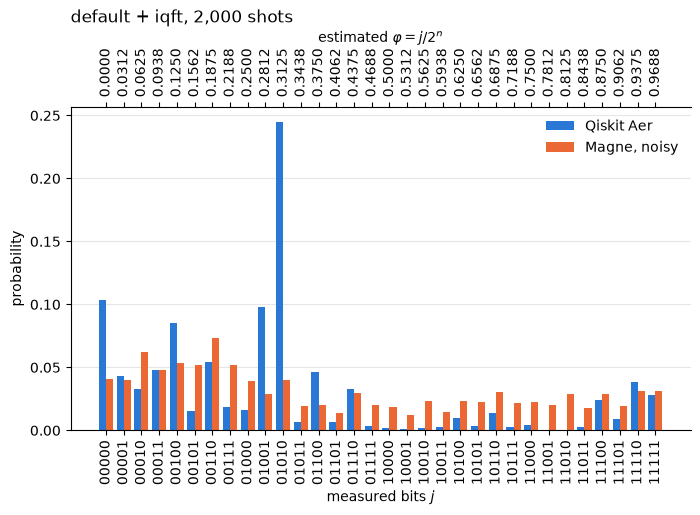

In [5]:
noise = magne_noise()
p_magne = run_neutral_atom(qc, shots=SHOTS, noise=noise, seed=1)
j = int(np.argmax(p_magne))
print(f"Magne: most likely j = {j:0{n}b} (p = {p_magne[j]:.3f})  ->  phi ~ {j / 2**n:.4f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(2**n)
ax.bar(x - 0.2, p_aer, width=0.4, color=COLORS[0], label="Qiskit Aer")
ax.bar(x + 0.2, p_magne, width=0.4, color=COLORS[1], label="Magne, noisy")
phase_axes(ax, n)
style(ax, f"{PREP.value} + {READOUT.value}, {SHOTS:,} shots", "measured bits $j$", "probability")
ax.legend(frameon=False)
plt.show()

## DPSS on Aer and Magne

The same run with the DPSS preparation. The dots are the noiseless DPSS distribution from `exact` on the coherent IQFT circuit: a slightly wider main peak, but with the plain layer's sinc^2 sidelobes suppressed.

/home/miran/Dokumenter/KU/Year 2/MQS-Prep/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/miran/Dokumenter/KU/Year 2/MQS-Prep/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


Aer   : most likely j = 01010 (p = 0.114)  ->  phi ~ 0.3125, TVD from noiseless 0.845
Magne : most likely j = 00110 (p = 0.062)  ->  phi ~ 0.1875, TVD from noiseless 0.908


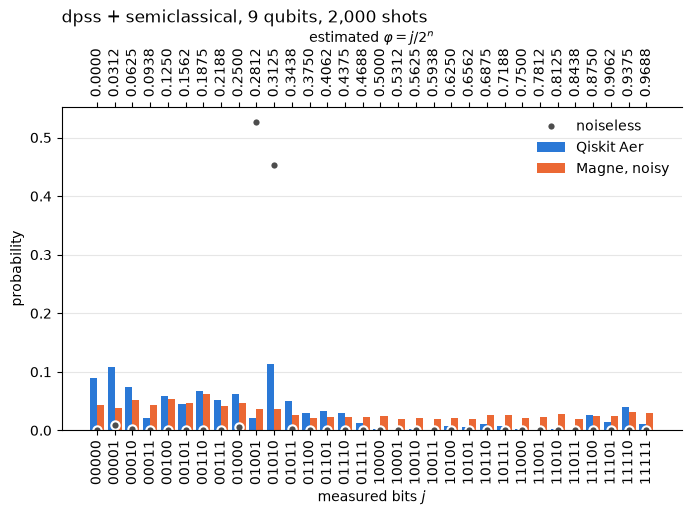

In [6]:
qc_dpss = build_qpe(Prep.DPSS, Readout.SEMICLASSICAL, U, initial_state, n)
p_dpss_ideal = exact(build_qpe(Prep.DPSS, Readout.IQFT, U, initial_state, n))
p_dpss_aer = sample(qc_dpss, shots=SHOTS)
p_dpss_magne = run_neutral_atom(qc_dpss, shots=SHOTS, noise=noise, seed=1)
for name, p in [("Aer", p_dpss_aer), ("Magne", p_dpss_magne)]:
    j = int(np.argmax(p))
    print(f"{name:6}: most likely j = {j:0{n}b} (p = {p[j]:.3f})  ->  phi ~ {j / 2**n:.4f}, "
          f"TVD from noiseless {0.5 * np.abs(p - p_dpss_ideal).sum():.3f}")

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(2**n)
ax.bar(x - 0.2, p_dpss_aer, width=0.4, color=COLORS[0], label="Qiskit Aer")
ax.bar(x + 0.2, p_dpss_magne, width=0.4, color=COLORS[1], label="Magne, noisy")
ax.plot(x, p_dpss_ideal, "o", ms=6, color="0.3", mec="white", mew=1.5, label="noiseless")
phase_axes(ax, n)
style(ax, f"dpss + semiclassical, {qc_dpss.num_qubits} qubits, {SHOTS:,} shots", "measured bits $j$", "probability")
ax.legend(frameon=False)
plt.show()

DPSS with the compact readout: the MPS staircase walks down the register one qubit at a time, so each counting qubit is finished, read and reset before the next gate needs a fresh one. That recycles on `k = 3` counting qubits, the width of the widest MPS gate.

/home/miran/Dokumenter/KU/Year 2/MQS-Prep/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:653: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/home/miran/Dokumenter/KU/Year 2/MQS-Prep/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_matfuncs.py:706: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


dpss + compact: 9 qubits, {'if_else': 10, 'h': 5, 'measure': 5, 'unitary': 3, 'x': 2, 'cU^16': 1, 'cU^8': 1, 'cU^4': 1, 'cU^2': 1, 'cU^1': 1}




In [7]:
qc_dpss_compact = build_qpe(Prep.DPSS, Readout.COMPACT, U, initial_state, n, k=3)
print(f"dpss + compact: {qc_dpss_compact.num_qubits} qubits, {dict(qc_dpss_compact.count_ops())}")
qc_dpss_compact.draw("mpl", fold=-1)

## Atom movement

In [8]:
show_atoms(qc)

## Every combination against the classical answer

The classical answer diagonalises U and reads off the eigenphase belonging to the target state. Each circuit is scored three ways: its point estimate `argmax j / 2^n` and that estimate's error, and its TVD from the noiseless distribution for the same preparation (every readout gives the same noiseless distribution, so `exact` on the coherent IQFT circuit is the reference).

In [9]:
U

Instruction(name='PauliEvolution', num_qubits=4, num_clbits=0, params=[1.0])

In [16]:
# classical: eigendecomposition of U
U_matrix = U.to_matrix()
eigvals, eigvecs = np.linalg.eig(U_matrix)
eigphases = np.angle(eigvals) / (2 * np.pi) % 1
initial_statevector = Statevector.from_instruction(initial_state).data
overlaps = np.abs(eigvecs.conj().T @ initial_statevector)
phi_true = eigphases[np.argmax(overlaps)]  # eigenvector closest to the target state
print("classical eigenphases:", np.round(np.sort(eigphases), 6), f" -> target's phi = {phi_true:.6f}")
print(f"best a {n}-bit estimate can do: {round(phi_true * 2**n) % 2**n / 2**n:.4f}\n")

circular = lambda a, b: min(abs(a - b), 1 - abs(a - b))  # phases wrap at 1
backends = {"aer": lambda qc: sample(qc, shots=SHOTS),
            "magne": lambda qc: run_neutral_atom(qc, shots=SHOTS, noise=noise, seed=1)}

results = {}  # (prep, readout, backend) -> (estimate, error, tvd)
print(f"{'prep':8}{'readout':15}{'backend':8}{'phi est':>9}{'error':>9}{'TVD':>8}")
for prep in Prep:
    reference = exact(build_qpe(prep, Readout.IQFT, U, initial_state, n, k))
    for readout, (name, run) in product(Readout, backends.items()):
        try:
            circuit = build_qpe(prep, readout, U, initial_state, n, k)
        except ValueError as err:
            print(f"{prep.value:8}{readout.value:15}{name:8}  skipped: {err}")
            continue
        p = run(circuit)
        est = int(np.argmax(p)) / 2**n
        results[prep, readout, name] = est, circular(est, phi_true), 0.5 * np.abs(p - reference).sum()
        print(f"{prep.value:8}{readout.value:15}{name:8}{est:9.4f}{results[prep, readout, name][1]:9.4f}{results[prep, readout, name][2]:8.3f}")

classical eigenphases: [0.035796 0.056233 0.056233 0.075105 0.075105 0.14049  0.18472  0.18472
 0.198082 0.198082 0.198082 0.199953 0.199953 0.295595 0.965897 1.      ]  -> target's phi = 0.295595
best a 5-bit estimate can do: 0.2812

prep    readout        backend   phi est    error     TVD
default iqft           aer        0.3125   0.0169   0.532
default iqft           magne      0.1875   0.1081   0.765
default semiclassical  aer        0.3125   0.0169   0.521
default semiclassical  magne      0.1875   0.1081   0.751
default compact        aer        0.3125   0.0169   0.533
default compact        magne      0.0625   0.2331   0.769
dpss    iqft           aer        0.3125   0.0169   0.847
dpss    iqft           magne      0.1875   0.1081   0.899
dpss    semiclassical  aer        0.3125   0.0169   0.845
dpss    semiclassical  magne      0.1875   0.1081   0.908
dpss    compact        aer       skipped: this staircase prepares every counting qubit at once, so none can be recycled: qubits

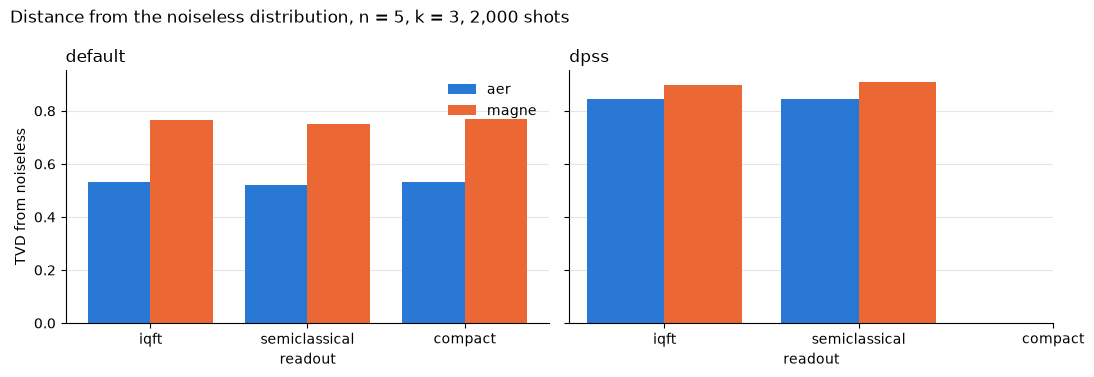

In [17]:
fig, axes = plt.subplots(1, len(Prep), figsize=(11, 3.8), sharey=True)
for ax, prep in zip(axes, Prep):
    for i, name in enumerate(backends):
        tvds = [results.get((prep, r, name), (0, 0, np.nan))[2] for r in Readout]
        ax.bar(np.arange(len(Readout)) + (i - 0.5) * 0.4, tvds, width=0.4, color=COLORS[i], label=name)
    ax.set_xticks(range(len(Readout)), [r.value for r in Readout])
    style(ax, prep.value, "readout", "TVD from noiseless" if ax is axes[0] else "")
axes[0].legend(frameon=False)
fig.suptitle(f"Distance from the noiseless distribution, n = {n}, k = {k}, {SHOTS:,} shots", x=0.01, ha="left")
plt.tight_layout()
plt.show()